# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [3]:
# TODO 1: one 1080p RGB frame, in MB
frame_bytes = 1920 * 1080 * 3 * 1
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = frame_bytes * frames_per_day * 400 / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = 640 * 360 * 3 * (10 * 24 * 3600) * 400 / 1024**4
pct_pixels_remaining = 640 * 360 / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ Spatial: at 640×360 (only ~11% of the pixels) fine detail like a face or number plate is lost and can't be recovered by interpolation. Temporal: at 10 fps fast actions (a hand throwing something, the exact moment of the break) can fall between frames, making motion correspondence ambiguous.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

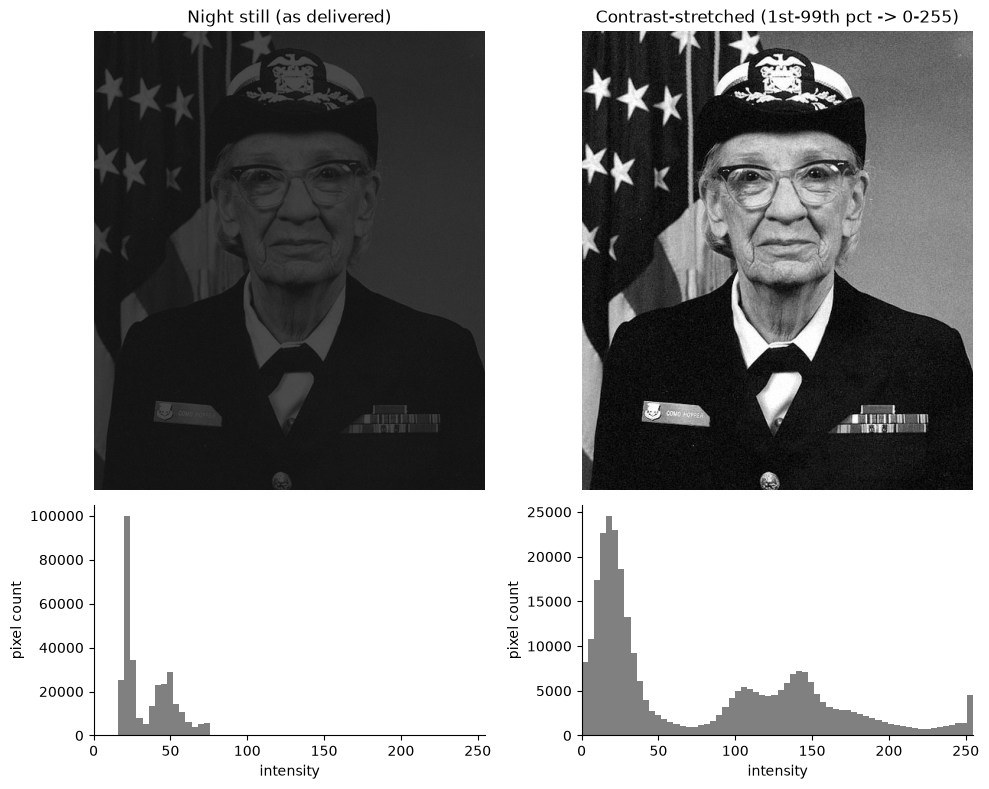

Contrast before: 0.609  ->  after: 1.000


In [4]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for j, (im, name) in enumerate([(night_still, "Night still (as delivered)"), (stretched, "Contrast-stretched (1st-99th pct -> 0-255)")]):
    axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(name); axes[0, j].axis("off")
    axes[1, j].hist(im.ravel(), bins=64, range=(0, 255), color="grey")
    axes[1, j].set_xlim(0, 255); axes[1, j].set_xlabel("intensity"); axes[1, j].set_ylabel("pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The histogram is narrow and bunched in the dark/low end (low-contrast, under-exposed). Stretching only remaps the existing levels over the full 0–255 range, so differences become visible without adding information; and a histogram discards spatial arrangement, so very different images can share the same histogram.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

standing: 68.7 s -> 78.1 s
running:  78.6 s -> 86.0 s
car arrives     frame   600  t = 20.0 s
person appears  frame  1200  t = 40.0 s
person stands   frame  2061  t = 68.7 s
loud bang       frame  2250  t = 75.0 s
person runs     frame  2358  t = 78.6 s
lights change   frame  3000  t = 100.0 s


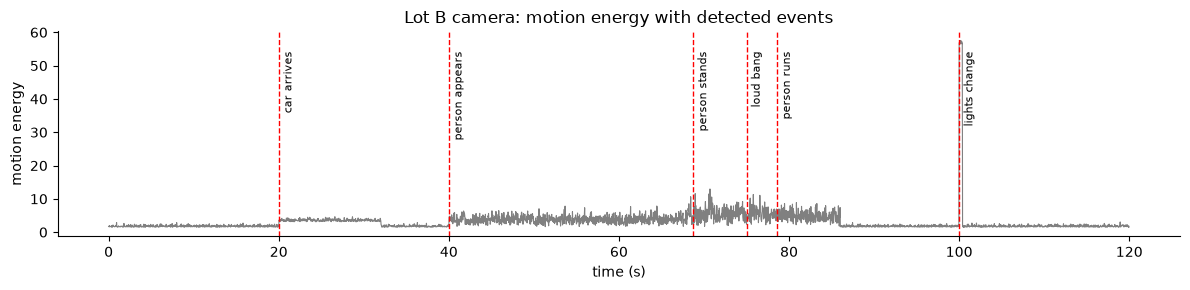

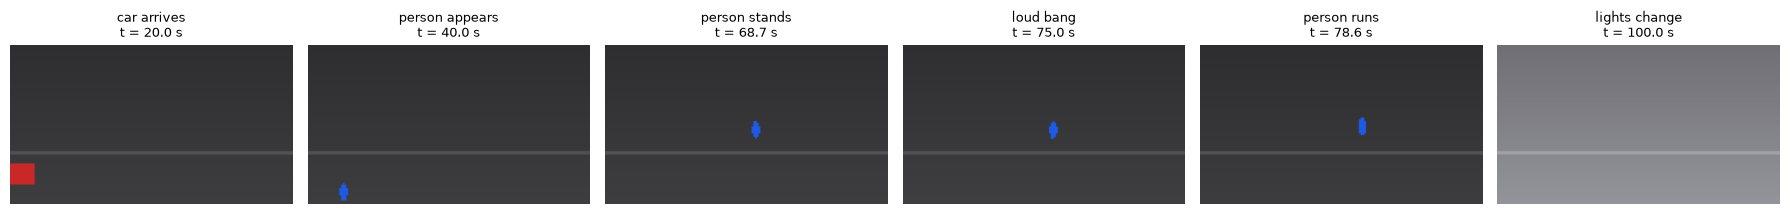

In [5]:
# TODO 1: person speed (px/s)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))     # displacement over 1 s = px/s

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = cctv.time_s[speed < 3]
running = cctv.time_s[speed > 25]
print(f"standing: {standing.min():.1f} s -> {standing.max():.1f} s")
print(f"running:  {running.min():.1f} s -> {running.max():.1f} s")

# TODO 3: event frame indices
audio_event_idx = int((cctv.audio_level_db > -20).values.argmax())
lighting_event_idx = int((cctv.mean_brightness.diff() > 40).values.argmax())

events = {
    "car arrives": int(cctv.car_x.notna().values.argmax()),
    "person appears": int(cctv.person_x.notna().values.argmax()),
    "person stands": int((speed < 3).values.argmax()),
    "loud bang": audio_event_idx,
    "person runs": int((speed > 25).values.argmax()),
    "lights change": lighting_event_idx,
}
for k, i in events.items():
    print(f"{k:15} frame {i:5d}  t = {cctv.time_s.iloc[i]:.1f} s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, lw=0.8, color="grey")
for k, i in events.items():
    t = cctv.time_s.iloc[i]
    ax.axvline(t, color="red", ls="--", lw=1)
    ax.text(t + 0.5, ax.get_ylim()[1] * 0.9, k, fontsize=8, rotation=90, va="top")
ax.set(xlabel="time (s)", ylabel="motion energy", title="Lot B camera: motion energy with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axs = plt.subplots(1, len(events), figsize=(3 * len(events), 2.4))
for ax, (k, i) in zip(axs, events.items()):
    ax.imshow(render_frame(cctv.iloc[i]))
    ax.set_title(f"{k}\nt = {cctv.time_s.iloc[i]:.1f} s", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ Short events like the bang at 75 s and the start of running (~79 s) would likely fall between samples at 0, 20, 40, 60, 80, 100 s. I used content-based (event-driven) keyframe selection instead.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

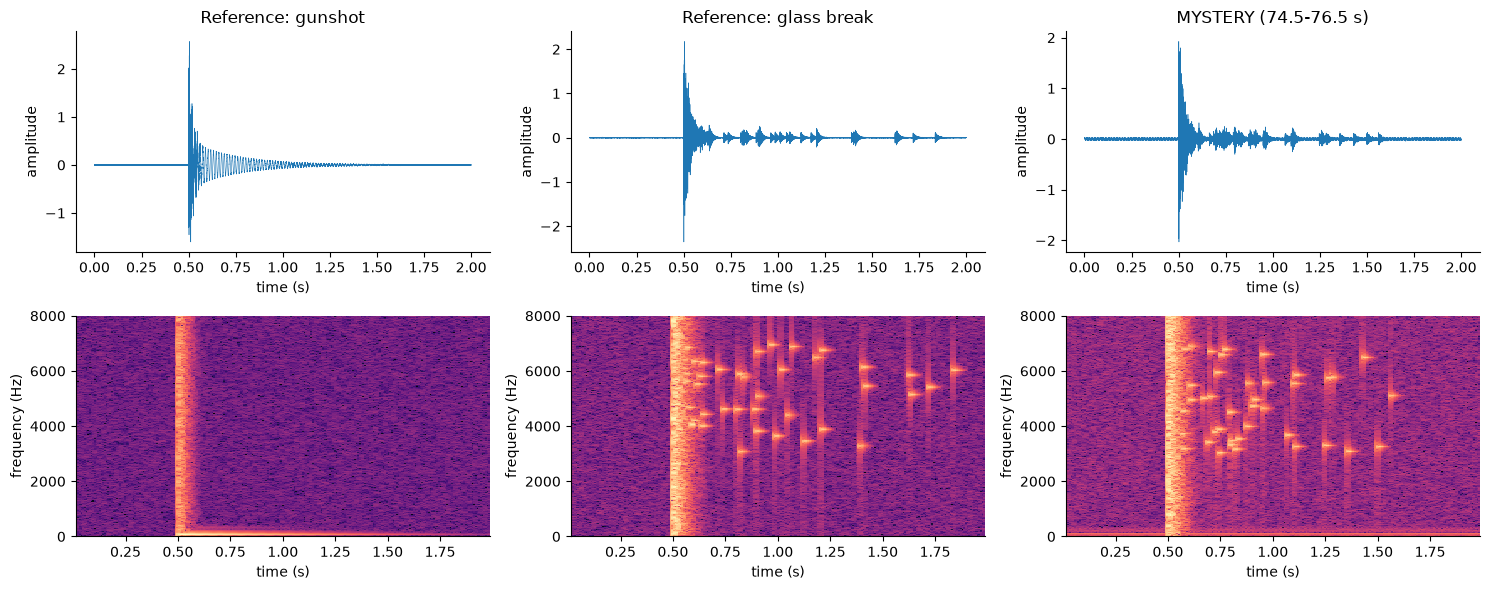

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: the mystery sound matches the GLASS BREAK (HF fraction 0.87 vs gunshot 0.00, glass 0.99).


In [6]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
specs = {}
for j, (name, x) in enumerate(clips.items()):
    t = np.arange(x.size) / FS
    axes[0, j].plot(t, x, lw=0.4)
    axes[0, j].set(title=name, xlabel="time (s)", ylabel="amplitude")
    f, tt, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    specs[name] = (f, tt, S)
    axes[1, j].pcolormesh(tt, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
    axes[1, j].set(ylim=(0, 8000), xlabel="time (s)", ylabel="frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, (f, tt, S) in specs.items():
    win = S[:, (tt >= 0.7) & (tt <= 1.7)]
    hf_fraction[name] = round(float(win[f > 3000].sum() / win.sum()), 3)

print(hf_fraction)
# TODO 4: verdict
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
closest = min(["Reference: gunshot", "Reference: glass break"], key=lambda k: abs(hf_fraction[k] - m))
print(f"Verdict: the mystery sound matches the {closest.split(': ')[1].upper()} (HF fraction {m:.2f} vs "
      f"gunshot {hf_fraction['Reference: gunshot']:.2f}, glass {hf_fraction['Reference: glass break']:.2f}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No — both waveforms are just a sharp spike that decays, so they look alike. The spectrogram adds time × frequency × magnitude (colour); the scattered high-frequency specks lingering after the impact identified glass, whereas the gunshot is a single vertical stripe plus a low band.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

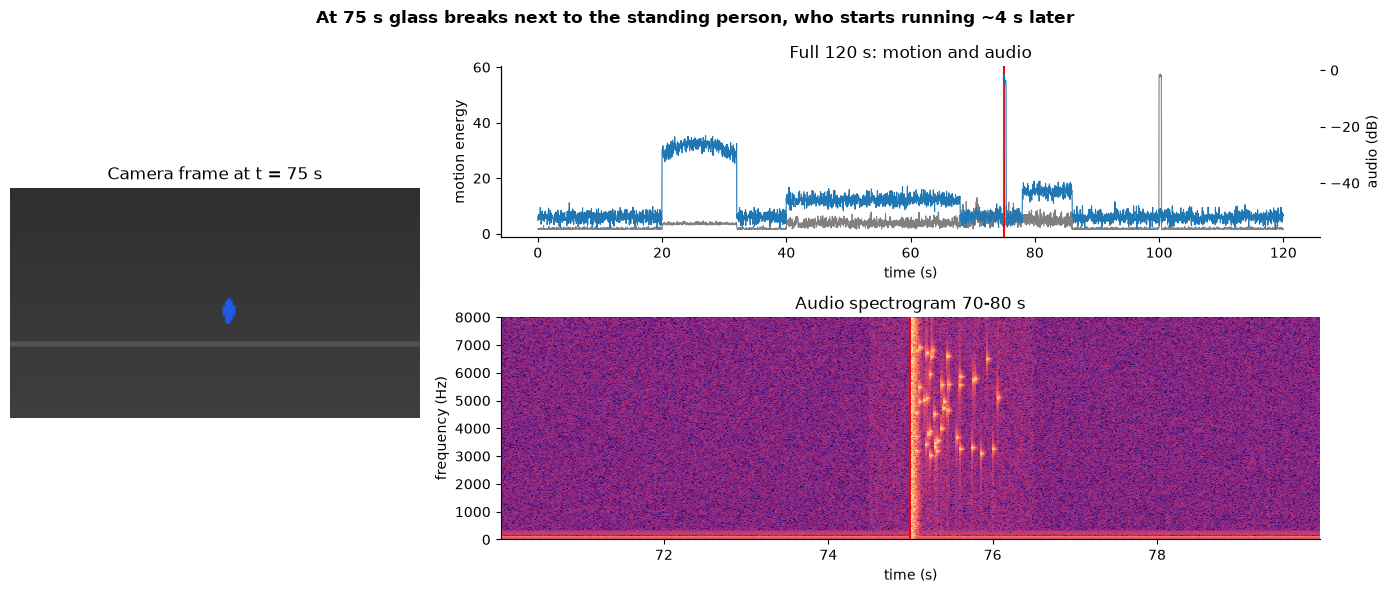

In [7]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
i_sel = int(np.argmin(np.abs(cctv.time_s.values - t_sel)))
ax_img = fig.add_subplot(gs[:, 0])
ax_img.imshow(render_frame(cctv.iloc[i_sel])); ax_img.axis("off")
ax_img.set_title(f"Camera frame at t = {t_sel:.0f} s")

ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv.time_s, cctv.motion_energy, lw=0.8, color="grey", label="motion energy")
ax_au = ax_tl.twinx()
ax_au.plot(cctv.time_s, cctv.audio_level_db, lw=0.8, color="tab:blue", label="audio level (dB)")
ax_tl.axvline(t_sel, color="red", lw=1.5)
ax_tl.set(xlabel="time (s)", ylabel="motion energy"); ax_au.set_ylabel("audio (dB)")
ax_tl.set_title("Full 120 s: motion and audio")

ax_sp = fig.add_subplot(gs[1, 1])
f, tt, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_sp.pcolormesh(tt + t_audio[0], f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
ax_sp.axvline(t_sel, color="red", lw=1.5)
ax_sp.set(ylim=(0, 8000), xlabel="time (s)", ylabel="frequency (Hz)", title="Audio spectrogram 70-80 s")

fig.suptitle("At 75 s glass breaks next to the standing person, who starts running ~4 s later", fontweight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ The bang would appear at 77 s, after the person started running, so we'd wrongly read the sound as a reaction to the running instead of its cause. The spectrogram panel's red marker vs the timeline/frame would show the mismatch.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ Between 20–32 s a car arrived, a person appeared at 40 s and stood still from ~69–78 s; at 75 s a glass-break sound occurred and the person ran off from ~79–86 s, followed by a lighting change at 100 s. I'd show the synchronized view first because it puts the event, its picture and its time × frequency × magnitude signature on one shared time axis. Store event-triggered clips at full resolution/fps and downsample the rest, but never sacrifice the synchronized audio track.